# Netflix Content Analysis: what is in the catalogue, and how has it changed?

This notebook walks through the full analysis step by step. It reuses the tested functions in `src/`, so every number here matches `python main.py`.

**Contents**
1. Load and clean the data
2. Data quality
3. Movies vs TV shows
4. Growth over time
5. Geography
6. Genres
7. Audience ratings
8. Duration
9. People
10. Text mining of descriptions
11. Statistical tests
12. Content-based recommender
13. Limitations

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import analysis as an
from src.cleaning import load_raw, clean
from src import plots  # applies the shared chart style

pd.set_option("display.max_columns", 30, "display.width", 140)
FIG = "../reports/figures/"
def show(name, width=760):
    display(Image(FIG + name, width=width))

## 1. Load and clean
The raw file is read as text, then cleaned in `src/cleaning.py`: whitespace is trimmed, `date_added` is parsed, runtime and seasons are split out of `duration`, and three rows with the runtime typed into the `rating` column are repaired.

In [2]:
raw = load_raw("../data/raw/netflix_data.csv")
print("Raw shape:", raw.shape)
raw.head(3)

Raw shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


In [3]:
misplaced = raw[raw["rating"].str.contains("min", na=False)][["title", "rating", "duration"]]
print("Rows where the runtime sits in the rating column:")
misplaced

Rows where the runtime sits in the rating column:


,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


In [4]:
df = clean(raw)
print("Clean shape:", df.shape)
df[["title", "type", "date_added", "year_added", "duration_min", "n_seasons", "rating", "rating_group", "primary_country"]].head()

Clean shape: (8807, 26)


,title,type,date_added,year_added,duration_min,n_seasons,rating,rating_group,primary_country
0,Dick Johnson Is Dead,Movie,2021-09-25,2021,90.0,NaN,PG-13,Teens,United States
1,Blood & Water,TV Show,2021-09-24,2021,NaN,2.0,TV-MA,Adults,South Africa
2,Ganglands,TV Show,2021-09-24,2021,NaN,1.0,TV-MA,Adults,NaN
3,Jailbirds New Orleans,TV Show,2021-09-24,2021,NaN,1.0,TV-MA,Adults,NaN
4,Kota Factory,TV Show,2021-09-24,2021,NaN,2.0,TV-MA,Adults,India


## 2. Data quality
Director is missing for roughly 3 in 10 titles; country and cast for about 1 in 10. Every analysis below that uses these columns drops the missing rows rather than guessing.

In [5]:
an.data_quality(df)

,missing,pct
n_seasons,6131,69.62
duration_min,2676,30.38
director,2634,29.91
country,831,9.44
primary_country,831,9.44
cast,825,9.37
date_added,10,0.11
year_added,10,0.11
month_added,10,0.11
weekday_added,10,0.11


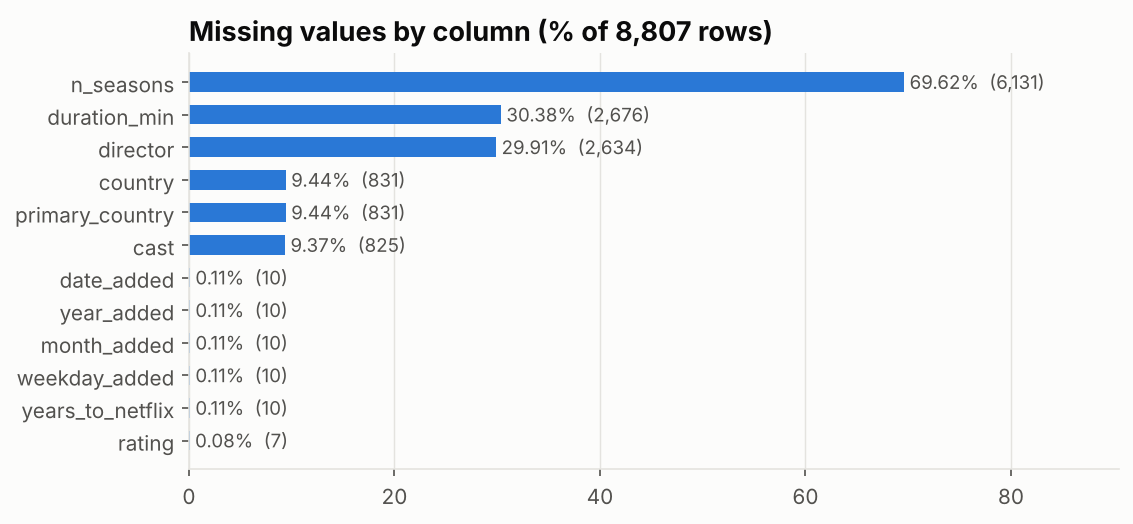

In [6]:
show('15_missing_values.png', 640)

## 3. Movies vs TV shows

In [7]:
an.type_split(df)

,titles,pct
type,,
Movie,6131,69.6
TV Show,2676,30.4


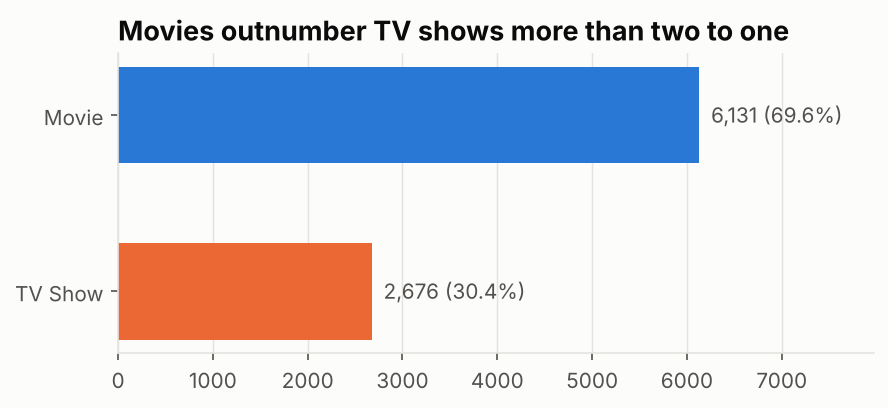

In [8]:
show('01_type_split.png', 560)

## 4. Growth over time
Additions were almost nil before 2015, then exploded. 2019 was the biggest year overall. 2021 only runs to 25 September, so its drop is partly an artefact.

In [9]:
an.additions_by_year(df).tail(8)

,Movie,TV Show
year_added,,
2014,19,5
2015,56,26
2016,253,176
2017,839,349
2018,1237,412
2019,1424,592
2020,1284,595
2021,993,505


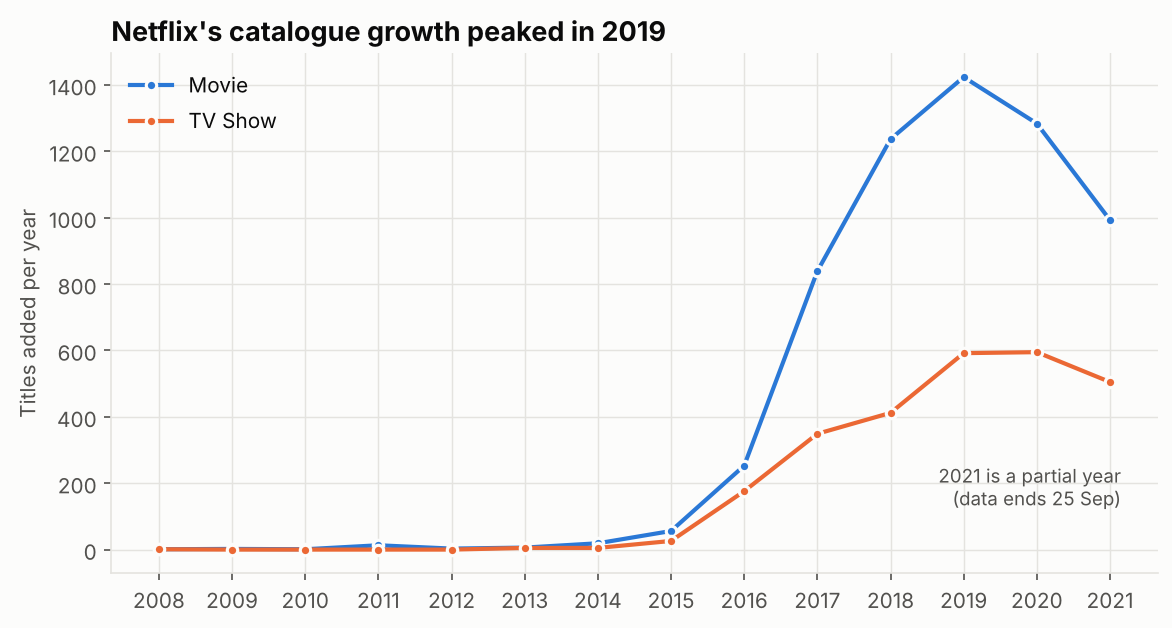

In [10]:
show('02_additions_by_year.png')

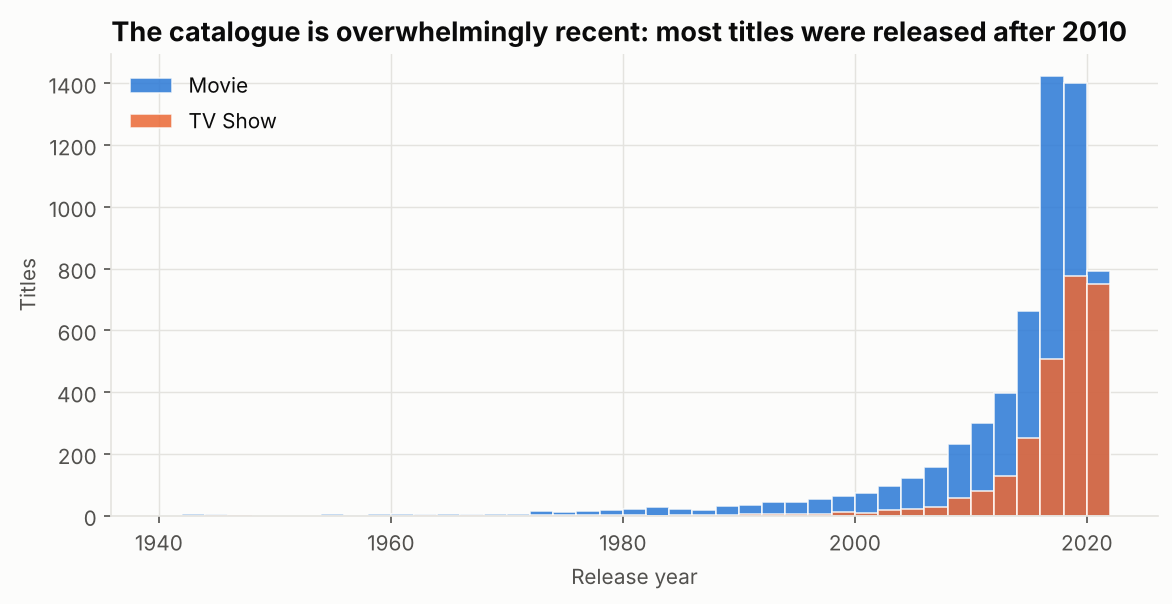

In [11]:
show('03_release_year_distribution.png')

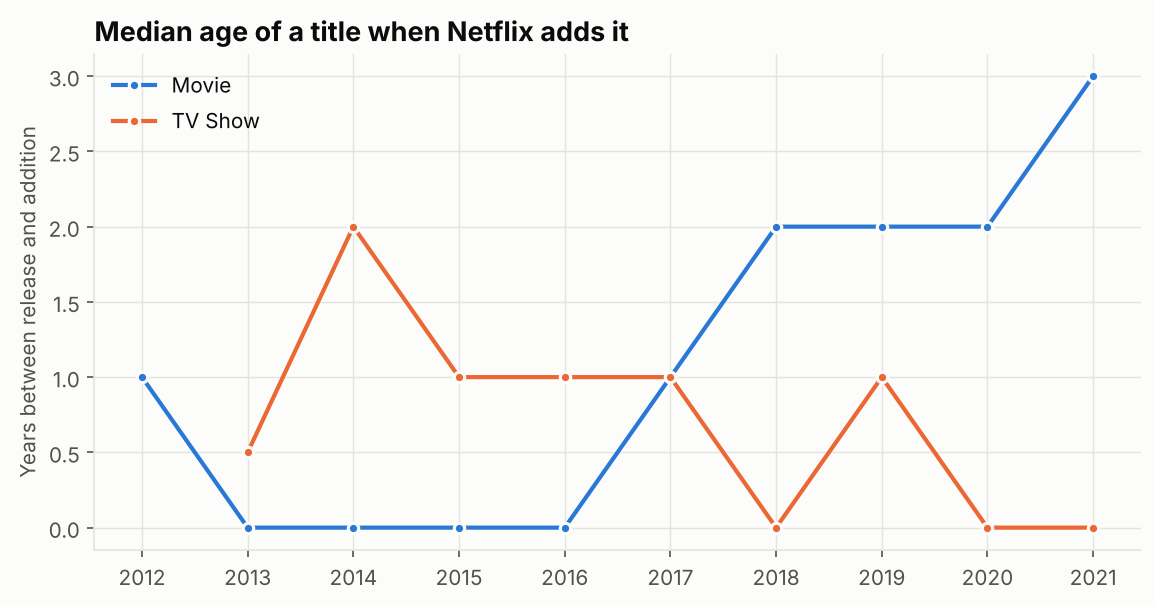

In [12]:
show('14_catalog_age_at_addition.png')

In [13]:
an.release_vs_added(df)

,count,mean,50%,75%,max
type,,,,,
Movie,6129.0,5.729972,2.0,7.0,75.0
TV Show,2654.0,2.314243,0.0,2.0,93.0


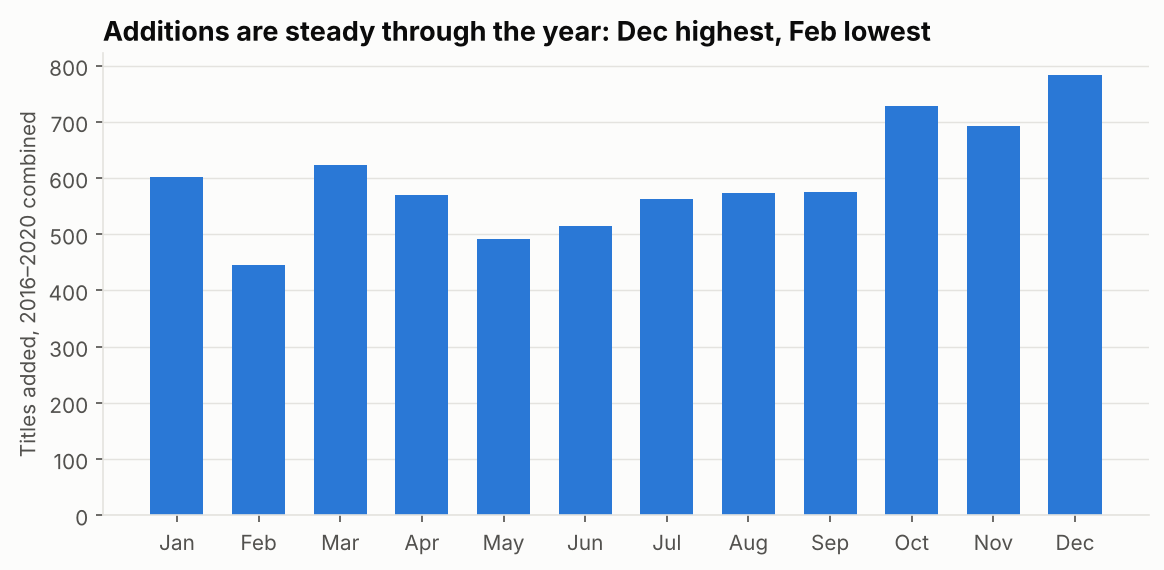

In [14]:
show('04_monthly_pattern.png')

## 5. Geography
Country is a comma-separated list, so a co-production counts once for each country.

In [15]:
an.top_countries(df, 12)

type,Movie,TV Show,total
nation,,,
United States,2752,938,3690
India,962,84,1046
United Kingdom,534,272,806
Canada,319,126,445
France,303,90,393
Japan,119,199,318
Spain,171,61,232
South Korea,61,170,231
Germany,182,44,226


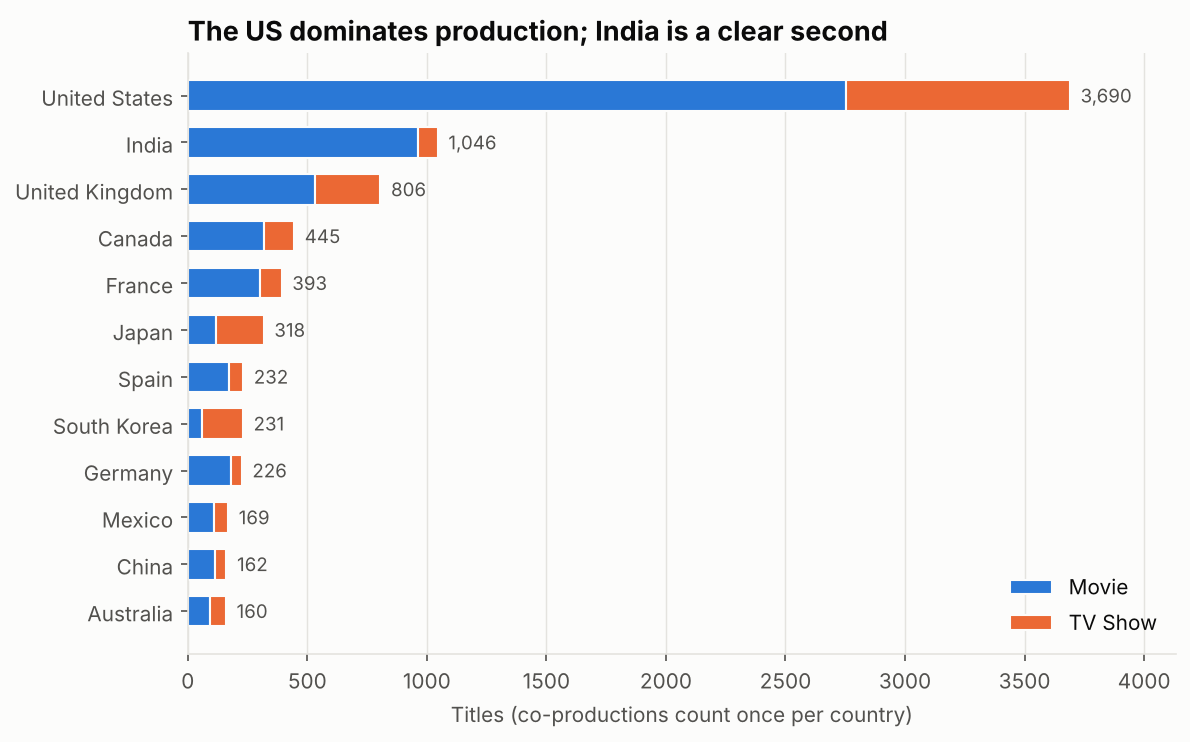

In [16]:
show('05_top_countries.png')

India's catalogue is almost all movies, while South Korea and Japan lean heavily to TV shows. The heatmap shows each country's genre fingerprint.

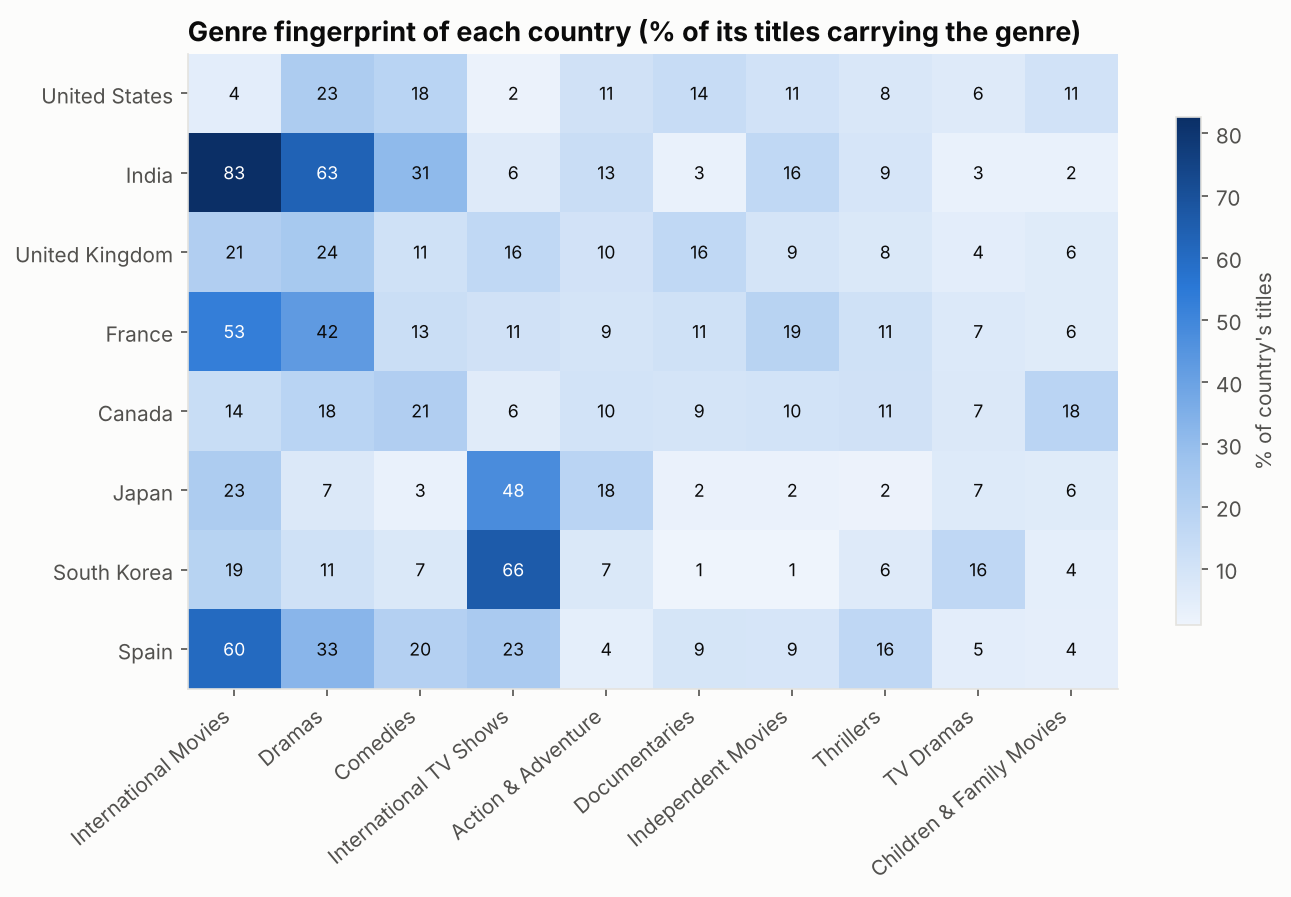

In [17]:
show('08_country_genre_heatmap.png')

## 6. Genres

In [18]:
an.genre_counts(df).head(12)

type,Movie,TV Show,total
genre,,,
International Movies,2752,0,2752
Dramas,2427,0,2427
Comedies,1674,0,1674
International TV Shows,0,1351,1351
Documentaries,869,0,869
Action & Adventure,859,0,859
TV Dramas,0,763,763
Independent Movies,756,0,756
Children & Family Movies,641,0,641


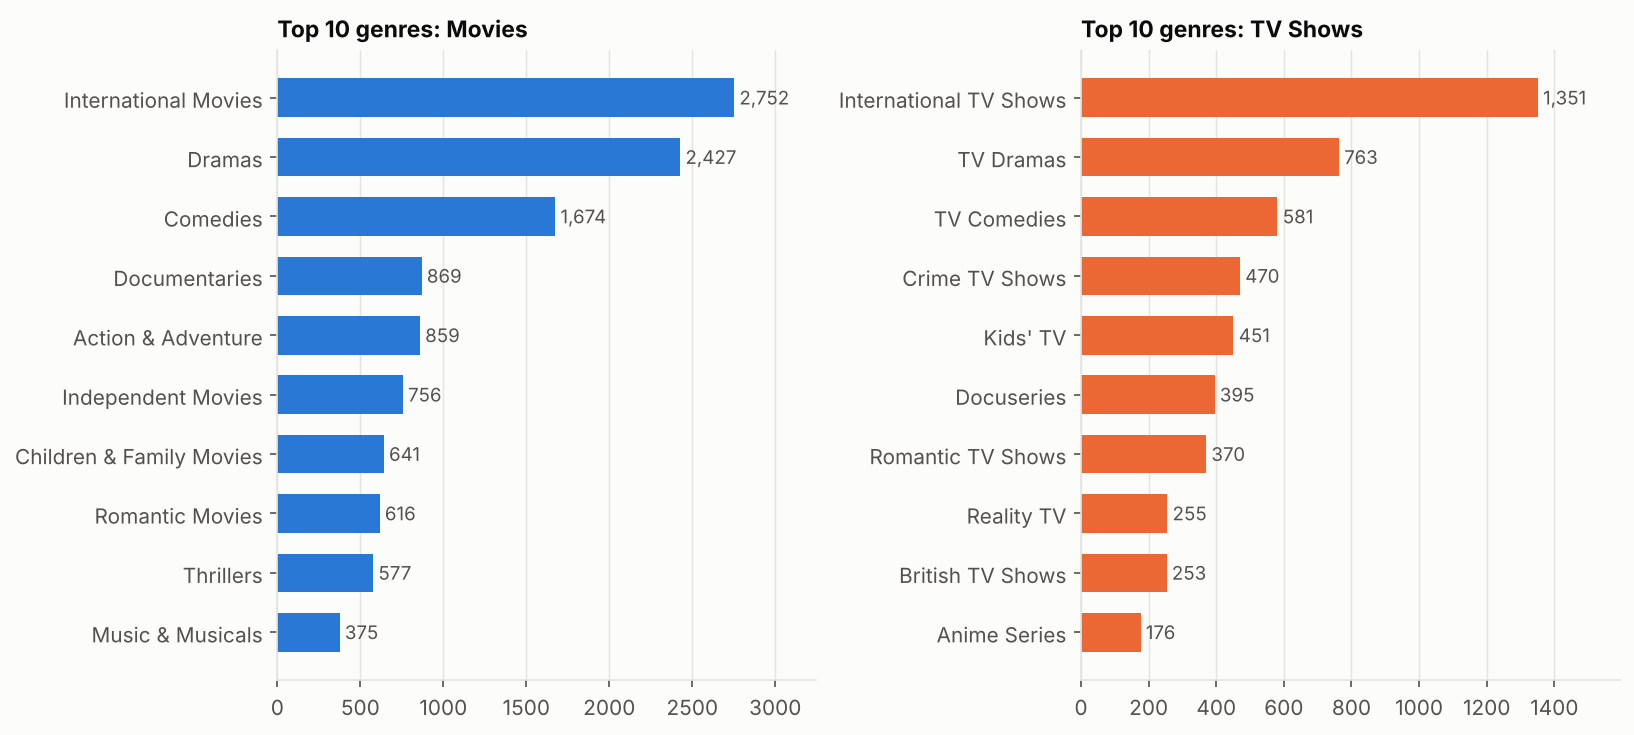

In [19]:
show('06_top_genres_by_type.png', 900)

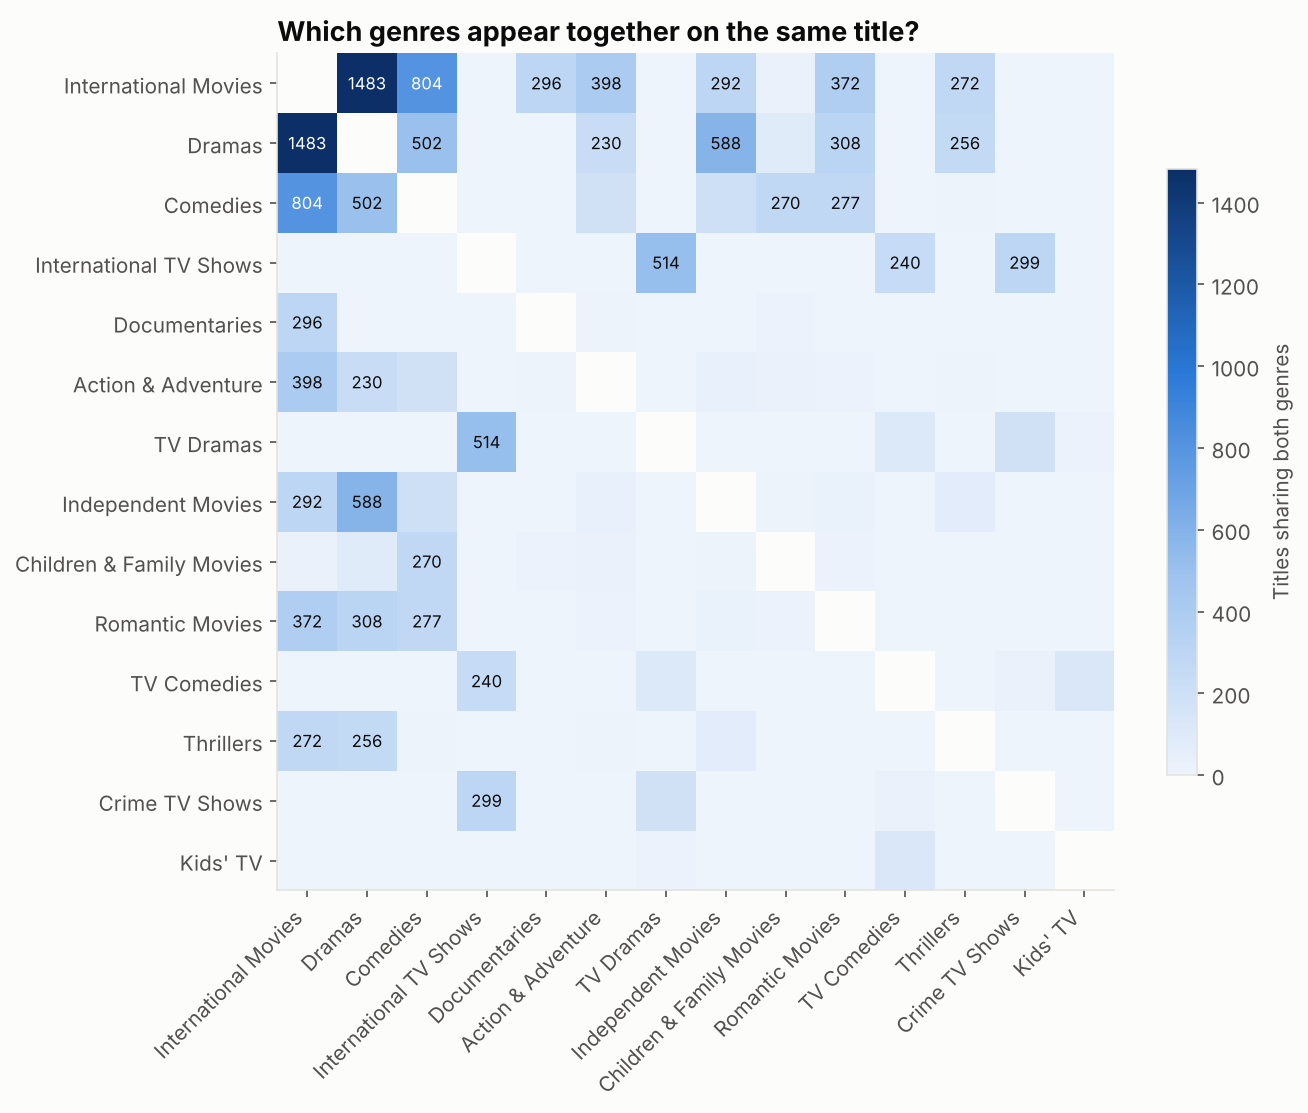

In [20]:
show('07_genre_cooccurrence.png', 700)

## 7. Audience ratings
Ratings are grouped into Kids, Family, Teens and Adults (see `RATING_GROUPS` in `src/cleaning.py`).

In [21]:
an.rating_counts(df)

type,Movie,TV Show,total
rating,,,
TV-MA,2062,1145,3207
TV-14,1427,733,2160
TV-PG,540,323,863
R,797,2,799
PG-13,490,0,490
TV-Y7,139,195,334
TV-Y,131,176,307
PG,287,0,287
TV-G,126,94,220


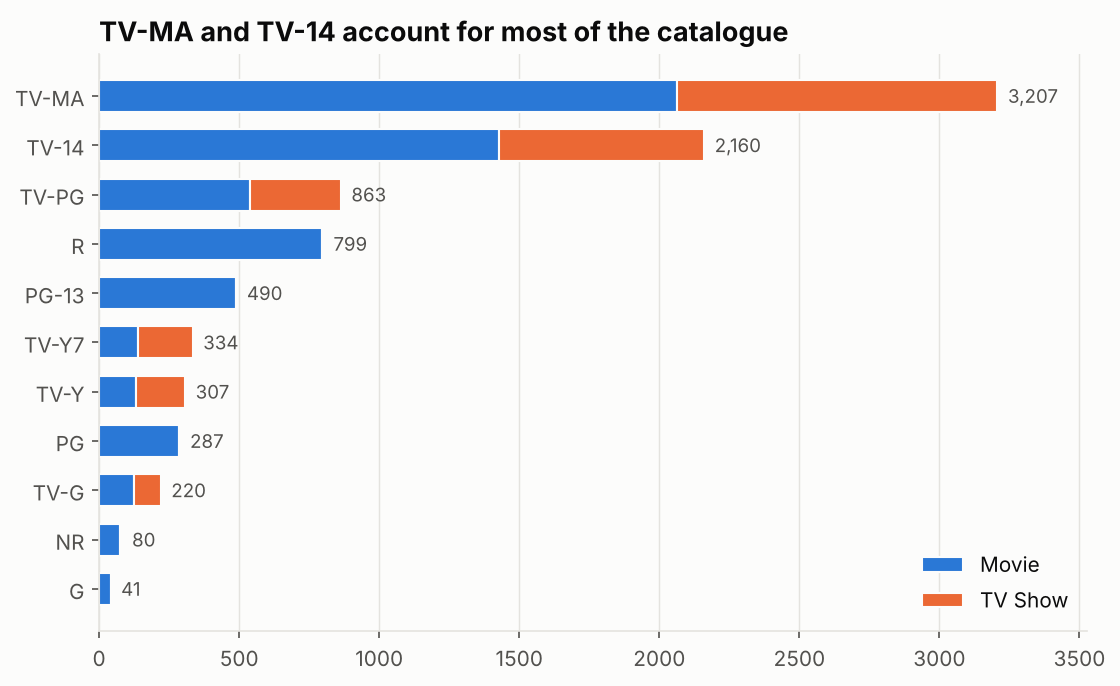

In [22]:
show('09_ratings.png')

In [23]:
an.maturity_share_by_year(df, 2016).round(1)

rating_group,Kids,Family,Teens,Adults
year_added,,,,
2016,16.3,13.3,26.1,44.4
2017,9.3,16.1,30.3,44.2
2018,8.2,13.3,30.8,47.7
2019,7.8,13.9,31.3,47.0
2020,12.1,12.3,29.9,45.7
2021,12.8,10.3,31.5,45.3


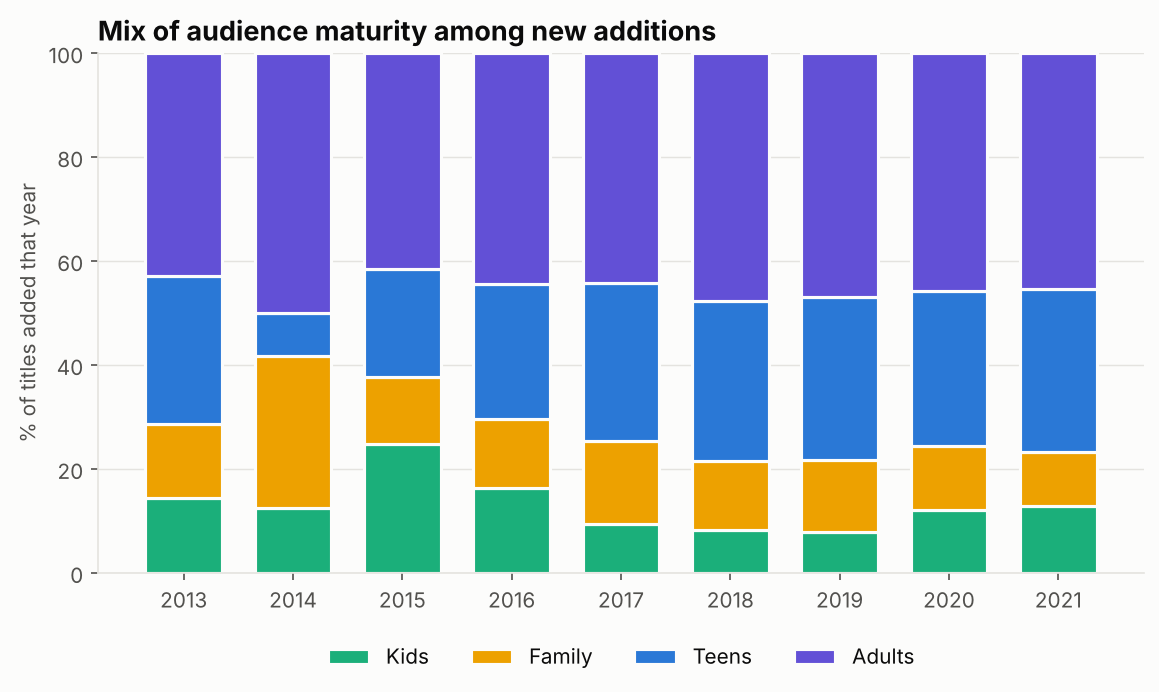

In [24]:
show('10_maturity_trend.png')

## 8. Duration

In [25]:
an.movie_runtime_by_decade(df)

,count,median,mean
release_decade,,,
1960,23,152.0,147.6
1970,66,113.5,119.2
1980,122,105.5,116.2
1990,241,108.0,113.8
2000,677,108.0,112.1
2010,4184,97.0,96.9
2020,794,97.0,93.6


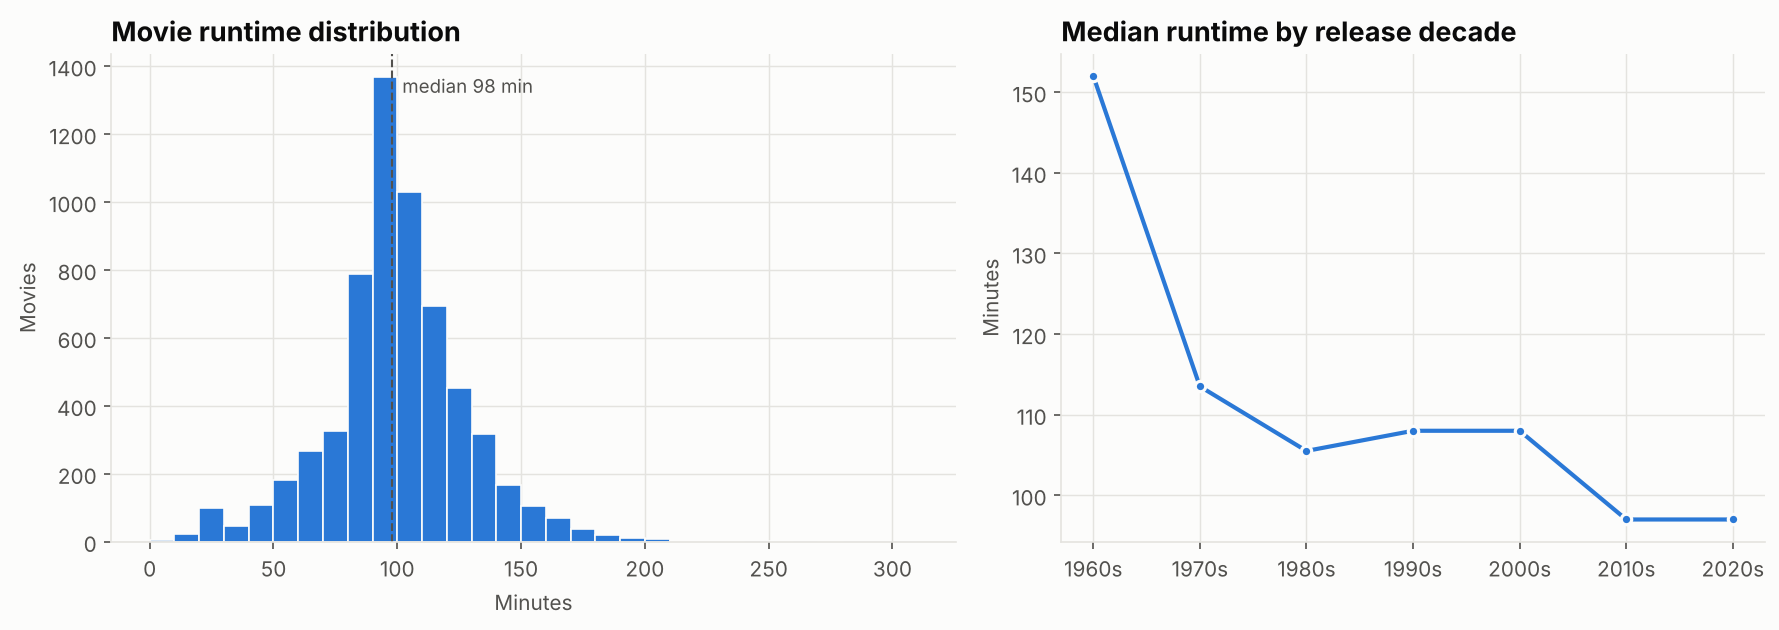

In [26]:
show('11_movie_runtime.png', 900)

In [27]:
an.tv_seasons(df).head(8)

n_seasons
1.0    1793
2.0     425
3.0     199
4.0      95
5.0      65
6.0      33
7.0      23
8.0      17
Name: count, dtype: int64

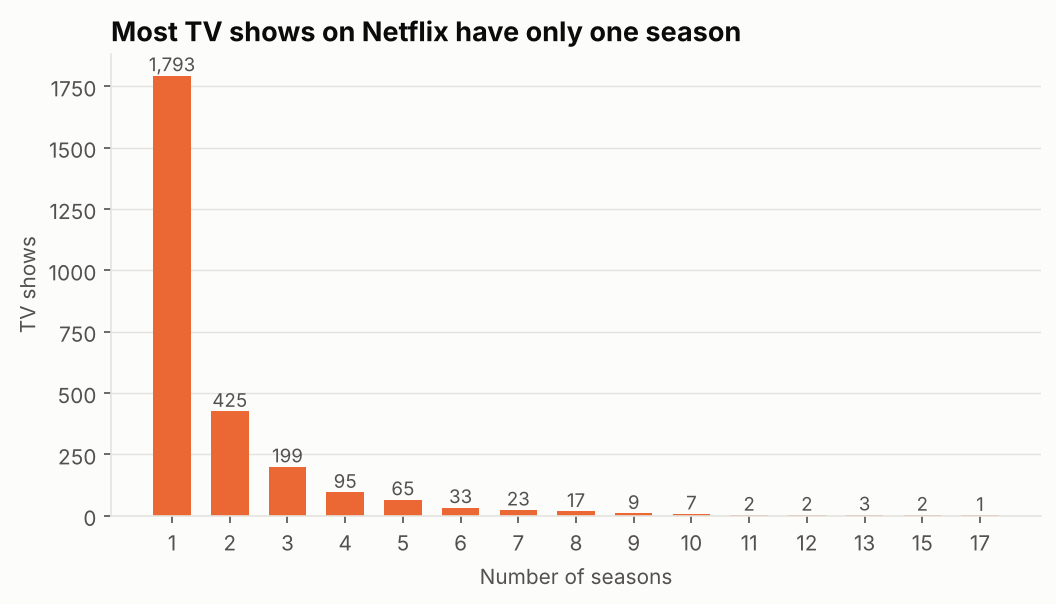

In [28]:
show('12_tv_seasons.png', 620)

## 9. People

In [29]:
an.top_people(df, 'director', 10)

type,Movie,TV Show,total
person,,,
Rajiv Chilaka,22,0,22
Jan Suter,21,0,21
Raúl Campos,19,0,19
Suhas Kadav,16,0,16
Marcus Raboy,15,1,16
Jay Karas,15,0,15
Cathy Garcia-Molina,13,0,13
Martin Scorsese,12,0,12
Jay Chapman,12,0,12


In [30]:
an.top_people(df, 'cast', 10)

type,Movie,TV Show,total
person,,,
Anupam Kher,42,1,43
Shah Rukh Khan,35,0,35
Julie Tejwani,28,5,33
Takahiro Sakurai,7,25,32
Naseeruddin Shah,32,0,32
Rupa Bhimani,27,4,31
Om Puri,30,0,30
Akshay Kumar,30,0,30
Yuki Kaji,10,19,29


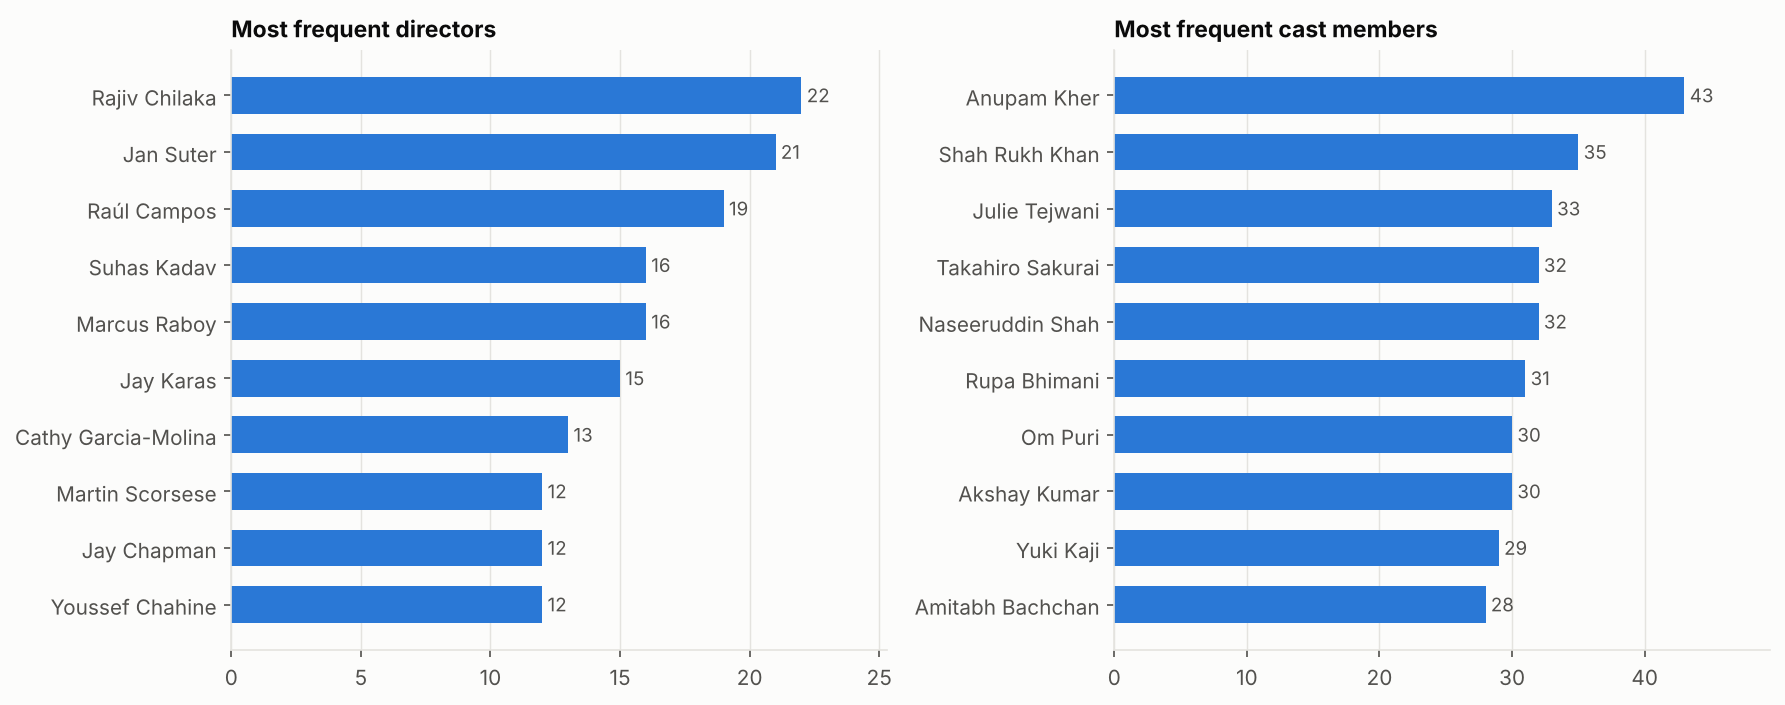

In [31]:
show('13_top_people.png', 900)

## 10. Text mining of descriptions
Two views: the words that best separate movie descriptions from TV descriptions (TF-IDF), and eight themes found with a non-negative matrix factorisation (NMF) topic model.

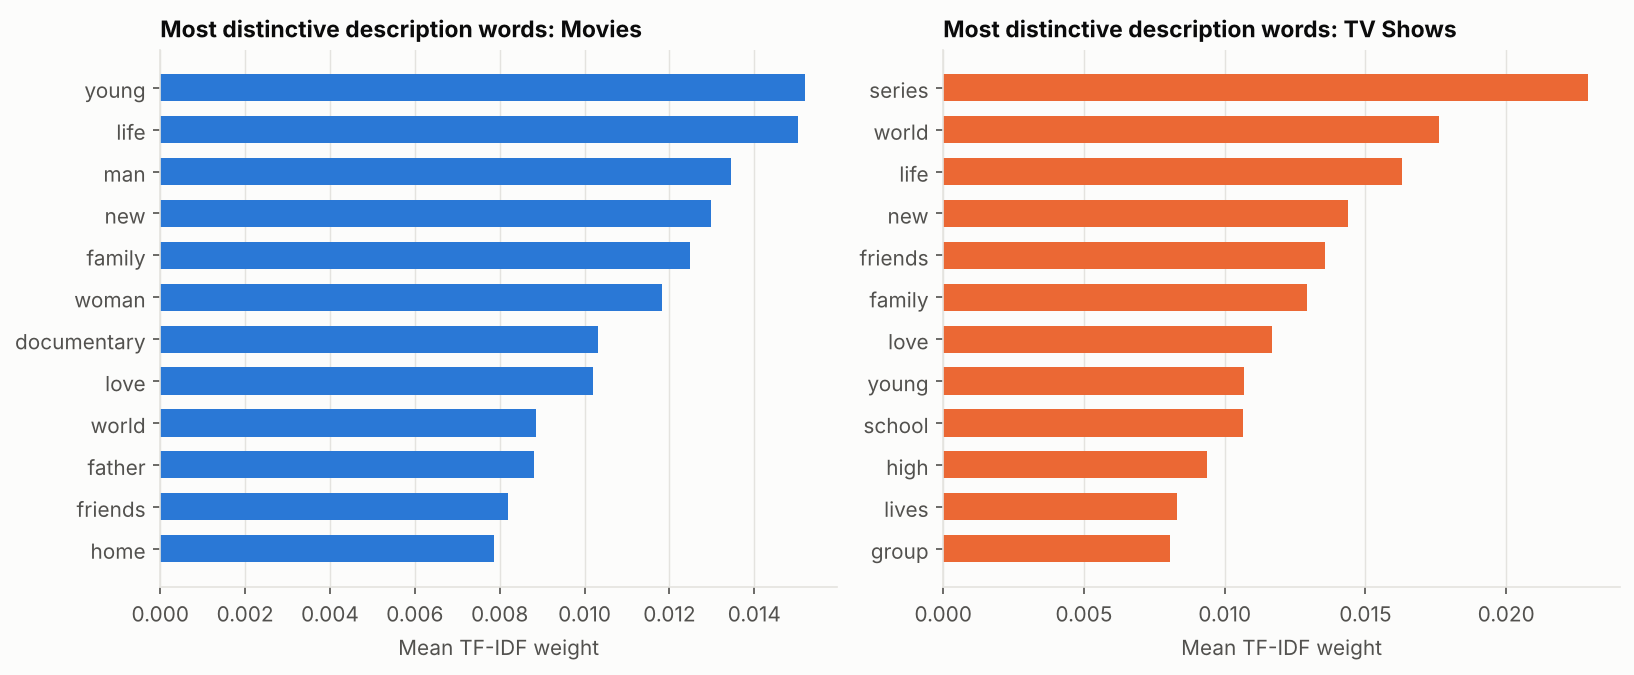

In [32]:
show('16_description_terms.png', 860)

In [33]:
topic_df, dominant = an.topic_model(df)
topic_df

,topic,top_words,titles,pct_tv
1,1,"young, man, woman, father, falls, finds, girl,...",1644,20.3
5,5,"family, old, year, father, home, son, daughter...",1485,25.9
0,0,"world, documentary, series, war, follows, ii, ...",1451,40.9
6,6,"friends, best, help, group, save, fun, friend,...",1134,36.1
3,3,"life, love, real, career, finds, death, romanc...",898,31.6
7,7,"stand, special, comedy, comedian, takes, comic...",753,24.2
4,4,"new, york, city, finds, home, town, soon, tries",726,31.7
2,2,"school, high, student, students, teen, girl, t...",716,36.2


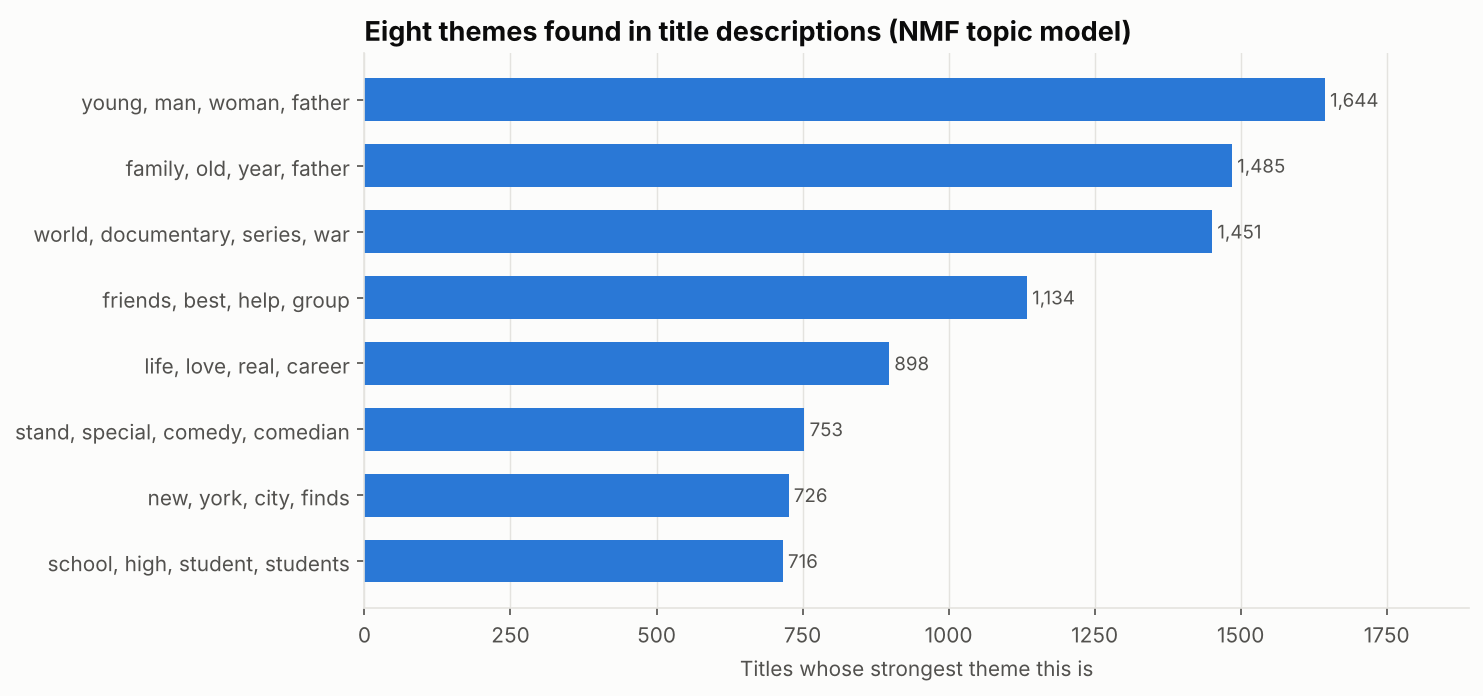

In [34]:
show('17_description_topics.png')

## 11. Statistical tests
These check whether three visible patterns are bigger than chance. With thousands of rows almost anything is 'significant', so read the effect sizes (rho, medians, Cramér's V) rather than the p-values.

In [35]:
import json
tests = an.statistical_tests(df)
print(json.dumps(tests, indent=2))

{
  "runtime_vs_release_year_spearman": {
    "rho": -0.191,
    "p": 1.753667855691508e-51,
    "n": 6131
  },
  "adult_vs_kids_family_runtime_mannwhitney": {
    "adult_median": 98.0,
    "kids_family_median": 90.0,
    "p": 2.4426259391068693e-44,
    "n_adult": 2862,
    "n_kids_family": 1269
  },
  "type_vs_rating_group_chi2": {
    "chi2": 228.0,
    "dof": 4,
    "p": 3.473389237604584e-48,
    "cramers_v": 0.161
  }
}


* **Runtime vs release year** (Spearman): a weak negative relationship, so newer movies tend to be somewhat shorter.
* **Adult-rated vs kids/family movies** (Mann-Whitney): adult-rated movies run longer, but the gap is only a few minutes at the median.
* **Type vs maturity group** (chi-square): a real but modest association (Cramér's V about 0.16).

## 12. Content-based recommender
TF-IDF over description, genres, cast and director, then cosine similarity. No viewing data is used, so this recommends *similar content*, not what people actually watched.

In [36]:
from src.recommender import ContentRecommender
rec = ContentRecommender(df)
rec.recommend("Narcos", 5)

,title,type,release_year,listed_in,similarity
0,Narcos: Mexico,TV Show,2020,"Crime TV Shows, TV Action & Adventure, TV Dramas",0.198
1,Wild District,TV Show,2019,"Crime TV Shows, International TV Shows, Spanis...",0.129
2,Miss Dynamite,TV Show,2015,"Crime TV Shows, International TV Shows, Spanis...",0.108
3,El Cartel,TV Show,2008,"Crime TV Shows, International TV Shows, Spanis...",0.097
4,Person of Interest,TV Show,2016,"Crime TV Shows, TV Action & Adventure, TV Dramas",0.096


In [37]:
rec.recommend('Stranger Things', 5)

,title,type,release_year,listed_in,similarity
0,Beyond Stranger Things,TV Show,2017,"Stand-Up Comedy & Talk Shows, TV Mysteries, TV...",0.499
1,Nightflyers,TV Show,2018,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.146
2,Chilling Adventures of Sabrina,TV Show,2020,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.144
3,Helix,TV Show,2015,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",0.140
4,Rowdy Rathore,Movie,2012,"Action & Adventure, Comedies, International Mo...",0.119


## 13. Limitations
* The data is a snapshot that ends on 25 Sep 2021 and contains no viewership, popularity or review scores, so nothing here says what people *watch*.
* `date_added` is the date a title was added to Netflix in the region the data was collected from, so country availability is not captured.
* Genres are Netflix's own tags; 'International Movies' is a catch-all that mixes very different films.
* Director is missing for about 30% of titles, so director rankings describe only the titles that list one.
* Counting titles per country double-counts co-productions by design.